# DSA4213 Assignment 1 — Part II: Embedding Ablation (LSTM)

**Requires:** `data/processed/*.txt` from Part I (or `python data/prepare_data.py`) in the same project folder.

**Attribution:** LSTM language model adapted from the DSA4213 Lecture 3 notebook (via Part I). Skip-gram via gensim `Word2Vec`; GloVe via `gensim.downloader`.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

Three settings, identical LSTM / tokenizer / vocabulary / training loop — **only the embedding layer changes**:

| Setting | Embedding init | Trained during LM training? |
|---|---|---|
| `random`  | random (PyTorch default) | yes, jointly with the LM |
| `own_sg`  | Skip-gram (Word2Vec) trained here on the WikiText-2 **train split only** | frozen |
| `public`  | public pretrained vectors (choose in Cell 2) | frozen |

Each setting is run with 3 seeds (42, 43, 44) so stability can be reported as mean ± std. A given seed fixes the LSTM initialisation and the batch order for **every** setting, so settings are also compared **paired by seed** (difference vs `random` within the same seed).
Runs that already finished are **skipped on re-run**, so a Colab disconnect only costs the run in progress.

In [ ]:
# ==========================================
# CELL 0: SETUP (identical in every notebook)
# ==========================================
import os, sys, subprocess, zipfile, urllib.request
from pathlib import Path
import torch

REPO_URL  = "https://github.com/LeuRNburgJoe11/DSA4213_Assignment.git"
REPO_NAME = "DSA4213_Assignment"
CKPT_URL  = ("https://github.com/LeuRNburgJoe11/DSA4213_Assignment/"
             "releases/download/v1.0/checkpoints.zip")

IN_COLAB  = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ   # Kaggle needs Settings > Internet: On (for git/gensim)

def _is_repo_root(p: Path) -> bool:
    return (p / "README.md").exists() and (p / "data" / "prepare_data.py").exists()

if IN_COLAB or IN_KAGGLE:
    PROJECT_DIR = Path("/content" if IN_COLAB else "/kaggle/working") / REPO_NAME
    if not PROJECT_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
else:
    here = Path.cwd().resolve()
    PROJECT_DIR = next((p for p in [here, *here.parents] if _is_repo_root(p)), here)

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "results" / "part2").mkdir(parents=True, exist_ok=True)

def require(path, hint=""):
    """Fail early with a clear message instead of deep inside a later cell."""
    if not (PROJECT_DIR / path).exists():
        raise FileNotFoundError(f"Missing {path}. {hint}")

def ensure_wikitext():
    """Rebuild data/processed/{train,valid,test}.txt if this runtime doesn't have them."""
    if not all((PROJECT_DIR / "data/processed" / f"{s}.txt").exists()
               for s in ("train", "valid", "test")):
        subprocess.run([sys.executable, "data/prepare_data.py"], check=True)

def ensure_rt_prepared():
    """Build data/prepared/rt_*.csv by executing the data-prep notebook in this runtime."""
    if all((PROJECT_DIR / "data/prepared" / f"rt_{s}.csv").exists()
           for s in ("train", "valid", "test")):
        return
    ensure_wikitext()
    require("data/raw/rotten_tomatoes_critic_reviews.csv",
            "Download it from Kaggle (see README > Data access) and upload it to data/raw/.")
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute",
                    "Part3_data_prep_RottenTomatoes.ipynb",
                    "--output", "/tmp/part3_prep_executed.ipynb"], check=True)

def ensure_checkpoints():
    """Fetch the trained LSTM checkpoints (Parts I-II) from the GitHub release."""
    have_p1 = (PROJECT_DIR / "results/lstm.pt").exists()
    have_p2 = len(list((PROJECT_DIR / "results/part2").glob("lstm_*.pt"))) >= 9
    if have_p1 and have_p2:
        return
    zpath = PROJECT_DIR / "checkpoints.zip"
    print("Downloading checkpoints from GitHub release ...")
    urllib.request.urlretrieve(CKPT_URL, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(PROJECT_DIR)  # contains results/lstm.pt and results/part2/lstm_*.pt
    zpath.unlink()

print("Working directory:", Path.cwd())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU available. In Colab, select: Runtime > Change runtime type > T4 GPU; "
          "in Kaggle: Settings > Accelerator > GPU T4 x2")

In [2]:
# ==========================================
# CELL 1: CONFIRM WIKITEXT DATA IS PRESENT
# ==========================================
ensure_wikitext()

In [ ]:
# ==========================================
# CELL 1b: INSTALL GENSIM (Word2Vec + pretrained-vector downloader)
# ==========================================
# gensim >= 4.4 supports NumPy 2, so no Colab runtime restart is needed.
try:
    import gensim
    assert tuple(map(int, gensim.__version__.split(".")[:2])) >= (4, 4)
except (ImportError, AssertionError):
    %pip install -q "gensim>=4.4.0"
    import gensim
print("gensim", gensim.__version__)

In [ ]:
# ==========================================
# CELL 2: EXPERIMENT CONFIG
# ==========================================
# EMBED_DIM is taken from the chosen public vectors so ALL THREE settings match.
PUBLIC_OPTIONS = {
    "glove-wiki-gigaword-100": dict(dim=100, desc="GloVe, Wikipedia 2014 + Gigaword 5 (6B tokens), "
                                                  "400k lowercase words, ~128 MB"),
}
PUBLIC_EMBEDDING = "glove-wiki-gigaword-100"          # the NAME (a string), used everywhere else

EMBED_DIM = PUBLIC_OPTIONS[PUBLIC_EMBEDDING]["dim"]
SETTINGS  = ["random", "own_sg", "public"]
SEEDS     = [42, 43, 44]   # 3 seeds -> mean ± std; finished runs are skipped on re-run

# Own Skip-gram hyperparameters (standard Word2Vec defaults, sg=1 selects Skip-gram)
SG_CFG = dict(vector_size=EMBED_DIM, window=5, sg=1, negative=5, min_count=1, epochs=5, workers=1, seed=42)

print(f"Public embedding: {PUBLIC_EMBEDDING} ({PUBLIC_OPTIONS[PUBLIC_EMBEDDING]['desc']})")
print(f"EMBED_DIM = {EMBED_DIM} | settings = {SETTINGS} | seeds = {SEEDS}")

Public embedding: glove-wiki-gigaword-100 (GloVe, Wikipedia 2014 + Gigaword 5 (6B tokens), 400k lowercase words, ~128 MB)
EMBED_DIM = 100 | settings = ['random', 'own_sg', 'public'] | seeds = [42, 43, 44]


In [ ]:
# ==========================================
# CELL 3: SHARED TOKENIZER + VOCAB (identical to Part I)
# ==========================================
import re, math, json, time, copy, random
from collections import Counter
import numpy as np

START_TOKEN, END_TOKEN = "<s>", "</s>"
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
TOKEN_PATTERN = re.compile(r"\w+(?:'\w+)?|[^\w\s]")
WIKITEXT_MARKERS = re.compile(r" @([-,.])@ ")

def clean_wikitext(line):
    return WIKITEXT_MARKERS.sub(r"\1", line)

def tokenize(text):
    return TOKEN_PATTERN.findall(clean_wikitext(text).lower().replace("’", "'"))

def read_lines(path):
    """List of token lists, one per non-empty line, each wrapped in <s> ... </s>."""
    out = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        toks = tokenize(line.strip())
        if toks:
            out.append([START_TOKEN, *toks, END_TOKEN])
    return out

def build_vocabulary(tokens, max_vocab_size=30000):
    counts = Counter(tokens)
    most_common = [t for t, _ in counts.most_common(max_vocab_size)]
    vocabulary = [PAD_TOKEN, UNK_TOKEN] + sorted(set(most_common) - {PAD_TOKEN, UNK_TOKEN})
    return {t: i for i, t in enumerate(vocabulary)}, vocabulary

data_dir = Path("data/processed")
results_dir = Path("results/part2"); results_dir.mkdir(parents=True, exist_ok=True)

train_lines = read_lines(data_dir / "train.txt")
valid_lines = read_lines(data_dir / "valid.txt")
test_lines  = read_lines(data_dir / "test.txt")
flatten = lambda lines: [t for line in lines for t in line]
train_tokens, valid_tokens, test_tokens = map(flatten, (train_lines, valid_lines, test_lines))

token_to_id, vocabulary = build_vocabulary(train_tokens, 30000)
train_counts = Counter(train_tokens)

assert len(vocabulary) == 30002
print(f"Train tokens: {len(train_tokens):,} | vocab: {len(vocabulary):,}")

Train tokens: 2,124,061 | vocab: 30,002


In [ ]:
# ==========================================
# CELL 4: OWN EMBEDDINGS — Skip-gram (Word2Vec) on the training split only
# ==========================================
from gensim.models import Word2Vec

# Train on the same <unk>-mapped token stream the LM sees, so every LM vocab
# item (incl. <s>, </s>, <unk>) gets a vector.
sg_sentences = [[t if t in token_to_id else UNK_TOKEN for t in line] for line in train_lines]
sg_path = results_dir / f"own_skipgram_{EMBED_DIM}d.model"

if sg_path.exists():
    sg_model = Word2Vec.load(str(sg_path))
    sg_time = json.loads((results_dir / "own_skipgram_cost.json").read_text())["train_time_s"]
    print(f"Loaded existing Skip-gram model (originally trained in {sg_time:.1f}s)")
else:
    t0 = time.perf_counter()
    sg_model = Word2Vec(sentences=sg_sentences, **SG_CFG)
    sg_time = time.perf_counter() - t0
    sg_model.save(str(sg_path))
    (results_dir / "own_skipgram_cost.json").write_text(json.dumps(
        {"train_time_s": sg_time, "config": SG_CFG, "n_tokens": len(train_tokens),
         "hardware": f"CPU x{os.cpu_count()}"}, indent=1))
    print(f"Trained Skip-gram in {sg_time:.1f}s on {os.cpu_count()} CPU cores")

# Sanity check (also a nice qualitative table for the report / appendix)
for probe in ["king", "french", "war", "river", "album", "1995"]:
    if probe in sg_model.wv:
        print(f"{probe:8s} -> {[w for w, _ in sg_model.wv.most_similar(probe, topn=5)]}")

Trained Skip-gram in 60.1s on 2 CPU cores
king     -> ['odaenathus', 'henry', 'dublin', 'lord', 'emperor']
french   -> ['german', 'warships', 'russian', 'british', 'italian']
war      -> ['outbreak', 'civil', 'conflict', 'ii', 'wars']
river    -> ['missouri', 'creek', 'mississippi', 'valley', 'susquehanna']
album    -> ['songs', 'studio', 'yankovic', 'slayer', 'band']
1995     -> ['1999', '1997', '1993', '1988', '1994']


In [ ]:
# ==========================================
# CELL 5: PUBLIC EMBEDDINGS — download + vocabulary coverage
# ==========================================
import gensim.downloader as gensim_api

# Since PUBLIC_EMBEDDING is already a string, we use it directly
public_name = PUBLIC_EMBEDDING

t0 = time.perf_counter()
public_kv = gensim_api.load(public_name)      # cached in ~/gensim-data after first download
public_load_time = time.perf_counter() - t0
print(f"Loaded {public_name}: {len(public_kv.index_to_key):,} words x {public_kv.vector_size}d "
      f"in {public_load_time:.0f}s")

def lookup(kv, token):
    """Exact match first; then capitalised / upper-case forms (for cased vectors like Google News)."""
    for cand in (token, token.capitalize(), token.upper()):
        if cand in kv.key_to_index:
            return cand
    return None

SPECIALS = {PAD_TOKEN, UNK_TOKEN, START_TOKEN, END_TOKEN}
real_words = [w for w in vocabulary if w not in SPECIALS]
found = [w for w in real_words if lookup(public_kv, w) is not None]
missing = [w for w in real_words if lookup(public_kv, w) is None]

in_vocab_train_tokens = sum(train_counts[w] for w in real_words)
covered_train_tokens = sum(train_counts[w] for w in found)
coverage = {
    "public_embedding": public_name,
    "vocab_types_covered": len(found), "vocab_types_total": len(real_words),
    "type_coverage": len(found) / len(real_words),
    "token_coverage": covered_train_tokens / in_vocab_train_tokens,
    "load_time_s": public_load_time,
}
(results_dir / f"coverage_{public_name}.json").write_text(json.dumps(coverage, indent=1))
print(f"Type coverage : {coverage['type_coverage']:.2%} ({len(found):,}/{len(real_words):,} vocab words)")
print(f"Token coverage: {coverage['token_coverage']:.2%} of in-vocabulary training tokens")
print("Most frequent missing words:", sorted(missing, key=lambda w: -train_counts[w])[:25])

[==================================================] 100.0% 128.1/128.1MB downloaded
Loaded glove-wiki-gigaword-100: 400,000 words x 100d in 65s
Type coverage : 96.39% (28,914/29,998 vocab words)
Token coverage: 99.66% of in-vocabulary training tokens
Most frequent missing words: ['°', '−', '×', 'magadheera', 'sorraia', 'degrom', '₹', 'isesi', 'toniná', 'coldrum', 'mkhedruli', 'vandernoot', '\ufeff', 'berhtwald', 'qedar', 'qedarites', 'kōsaku', '→', 'nuskhuri', 'xook', 'fastra', 'ganganelli', 'hygrometricus', 'mhalsa', 'paranthodon']


In [ ]:
# ==========================================
# CELL 6: BUILD EMBEDDING MATRICES (with explicit OOV policy)
# ==========================================
# OOV policy:
#   <pad>                  -> zeros
#   <unk>                  -> mean of the found vectors
#   other missing words    -> N(0, sigma^2), sigma = std of the source vectors
#                             (incl. <s>, </s>; they stay random when frozen)

def build_matrix(get_vector, seed=0):
    rng = np.random.default_rng(seed)
    matrix = np.zeros((len(vocabulary), EMBED_DIM), dtype=np.float32)
    found_mask = np.zeros(len(vocabulary), dtype=bool)
    for i, w in enumerate(vocabulary):
        if w == PAD_TOKEN:
            continue
        v = get_vector(w)
        if v is not None:
            matrix[i], found_mask[i] = v, True
    sigma = matrix[found_mask].std()
    for i, w in enumerate(vocabulary):
        if w == PAD_TOKEN or found_mask[i]:
            continue
        matrix[i] = matrix[found_mask].mean(0) if w == UNK_TOKEN else rng.normal(0, sigma, EMBED_DIM)
    return torch.tensor(matrix), int(found_mask.sum())

def public_vector(w):
    if w in SPECIALS:
        return None
    key = lookup(public_kv, w)
    return public_kv[key] if key is not None else None

def own_vector(w):
    return sg_model.wv[w] if w in sg_model.wv.key_to_index else None

own_matrix, own_found = build_matrix(own_vector)
public_matrix, public_found = build_matrix(public_vector)
print(f"own_sg : {own_found:,}/{len(vocabulary):,} rows from Skip-gram | mean L2 norm "
      f"{own_matrix.norm(dim=1).mean():.2f}")
print(f"public : {public_found:,}/{len(vocabulary):,} rows from {PUBLIC_EMBEDDING} | mean L2 norm "
      f"{public_matrix.norm(dim=1).mean():.2f}")

own_sg : 30,001/30,002 rows from Skip-gram | mean L2 norm 1.67
public : 28,914/30,002 rows from glove-wiki-gigaword-100 | mean L2 norm 5.05


In [ ]:
# ==========================================
# CELL 7: LSTM WITH PLUGGABLE EMBEDDING + SHARED TRAINING LOOP
# ==========================================
import torch.nn as nn

LSTM_CFG = dict(epochs=20, batch_size=64, sequence_length=32, embed_dim=EMBED_DIM, hidden_dim=256,
                learning_rate=1e-3, dropout=0.0, patience=2)

class LSTMLanguageModel(nn.Module):
    """Part I LSTM with tie_weights=False, so freezing the input table never freezes the output layer."""
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.0, pretrained=None, freeze=False):
        super().__init__()
        pad = token_to_id[PAD_TOKEN]
        if pretrained is None:
            self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad)
        else:
            self.embedding = nn.Embedding.from_pretrained(pretrained.clone(), freeze=freeze, padding_idx=pad)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Linear(hidden_dim, embed_dim)
        self.fc = nn.Linear(embed_dim, vocab_size)

    def forward(self, x, hidden=None):
        out, hidden = self.lstm(self.drop(self.embedding(x)), hidden)
        return self.fc(self.proj(self.drop(out))), hidden

def make_model(setting):
    common = dict(vocab_size=len(vocabulary), embed_dim=EMBED_DIM, hidden_dim=LSTM_CFG["hidden_dim"],
                  dropout=LSTM_CFG["dropout"])
    if setting == "random":    return LSTMLanguageModel(**common)
    if setting == "own_sg":    return LSTMLanguageModel(**common, pretrained=own_matrix, freeze=True)
    if setting == "public":    return LSTMLanguageModel(**common, pretrained=public_matrix, freeze=True)
    raise ValueError(setting)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

# ---- data: fixed-length windows kept on the GPU (no DataLoader) ----
L, B = LSTM_CFG["sequence_length"], LSTM_CFG["batch_size"]

def to_windows(tokens):
    unk = token_to_id[UNK_TOKEN]
    ids = torch.tensor([token_to_id.get(t, unk) for t in tokens], dtype=torch.long)
    n = (len(ids) - 1) // L
    return ids[:n * L].view(n, L).to(device), ids[1:n * L + 1].view(n, L).to(device)

data = {"train": to_windows(train_tokens), "valid": to_windows(valid_tokens), "test": to_windows(test_tokens)}
train_gen = torch.Generator()   # re-seeded per run -> same batch order for every setting at a given seed

def batches(split, shuffle=False):
    x, y = data[split]
    order = torch.randperm(len(x), generator=train_gen) if shuffle else torch.arange(len(x))
    order = order.to(device)
    for i in range(0, len(order), B):
        idx = order[i:i + B]
        yield x[idx], y[idx]

@torch.no_grad()
def evaluate(model, split, criterion):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for x, y in batches(split):
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits, _ = model(x)
        total_loss += criterion(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1)).item()
        total_tokens += (y != criterion.ignore_index).sum().item()
    bits = total_loss / total_tokens / math.log(2)
    return bits, 2 ** bits

# ---- one run = one (setting, seed); resumable per epoch ----
def run(setting, seed):
    name = f"{setting}_s{seed}"
    result_file = results_dir / f"result_{name}.json"
    ckpt_path = results_dir / f"inprogress_{name}.pt"
    if result_file.exists():
        print(f"[{name}] already done — skipping")
        return json.loads(result_file.read_text())

    set_seed(seed); train_gen.manual_seed(seed)
    model = make_model(setting).to(device)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=LSTM_CFG["learning_rate"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    criterion = nn.CrossEntropyLoss(ignore_index=token_to_id[PAD_TOKEN], reduction="sum")
    n_total, n_trainable = sum(p.numel() for p in model.parameters()), sum(p.numel() for p in trainable)

    history = {"epoch": [], "train_bits": [], "valid_bits": [], "valid_ppl": [], "epoch_time_s": []}
    best_ppl, best_state, bad, start = float("inf"), None, 0, 1
    if ckpt_path.exists():                                     # resume mid-run
        c = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        model.load_state_dict(c["model"]); optimizer.load_state_dict(c["opt"]); scaler.load_state_dict(c["scaler"])
        history, best_ppl, best_state, bad = c["history"], c["best_ppl"], c["best_state"], c["bad"]
        start = c["epoch"] + 1
        torch.set_rng_state(c["rng_cpu"]); train_gen.set_state(c["rng_gen"])
        if torch.cuda.is_available():
            torch.cuda.set_rng_state_all(c["rng_cuda"])
        print(f"[{name}] resuming from epoch {start}")
    print(f"\n=== {name}: {n_total:,} params ({n_trainable:,} trainable) ===")

    for epoch in range(start, LSTM_CFG["epochs"] + 1):
        if bad >= LSTM_CFG["patience"]:
            print(f"[{name}] early stopping after epoch {epoch - 1}")
            break
        model.train()
        tot_loss, tot_tok = torch.zeros((), device=device), 0
        sync(); t0 = time.perf_counter()
        for x, y in batches("train", shuffle=True):
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                logits, _ = model(x)
            loss = criterion(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1))
            scaler.scale(loss / y.numel()).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable, max_norm=1.0)
            scaler.step(optimizer); scaler.update()
            tot_loss += loss.detach(); tot_tok += y.numel()
        sync(); ep_time = time.perf_counter() - t0

        valid_bits, valid_ppl = evaluate(model, "valid", criterion)
        for k, v in zip(history, (epoch, tot_loss.item() / tot_tok / math.log(2), valid_bits, valid_ppl, ep_time)):
            history[k].append(v)
        print(f"[{name}] epoch {epoch:02d} | train CE {history['train_bits'][-1]:.3f} | "
              f"valid PPL {valid_ppl:8.2f} | {ep_time:5.1f}s")
        if valid_ppl < best_ppl:
            best_ppl, bad, best_state = valid_ppl, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
        torch.save({"model": model.state_dict(), "opt": optimizer.state_dict(), "scaler": scaler.state_dict(),
                    "history": history, "best_ppl": best_ppl, "best_state": best_state, "bad": bad,
                    "epoch": epoch, "rng_cpu": torch.get_rng_state(), "rng_gen": train_gen.get_state(),
                    "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None},
                   ckpt_path)                                    # outside the timer

    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "setting": setting, "seed": seed,
                "token_to_id": token_to_id, "vocabulary": vocabulary,
                "config": dict(LSTM_CFG, public_embedding=PUBLIC_EMBEDDING)},
               results_dir / f"lstm_{name}.pt")
    test_bits, test_ppl = evaluate(model, "test", criterion)

    best_epoch = int(np.argmin(history["valid_ppl"])) + 1
    within5 = next(e for e, p in zip(history["epoch"], history["valid_ppl"]) if p <= 1.05 * best_ppl)
    result = {"setting": setting, "seed": seed, "test_ppl": test_ppl, "test_ce_bits": test_bits,
              "best_valid_ppl": best_ppl, "valid_ppl_epoch1": history["valid_ppl"][0],
              "best_epoch": best_epoch, "epochs_to_within_5pct": within5,
              "epochs_run": len(history["epoch"]), "train_time_s": sum(history["epoch_time_s"]),
              "params_total": n_total, "params_trainable": n_trainable, "history": history}
    result_file.write_text(json.dumps(result, indent=1))
    ckpt_path.unlink()
    print(f"[{name}] TEST PPL {test_ppl:.2f} | best epoch {best_epoch} | within 5% of best at epoch {within5}")
    return result

In [ ]:
# ==========================================
# CELL 8: RUN SETTINGS x SEEDS (partition across independent notebook kernels)
# ==========================================
# To run jobs concurrently without sharing RNG state, use separate notebook kernels.
# In each kernel set PARALLEL_WORKERS to the number of kernels and assign a unique
# PARALLEL_WORKER_ID from 0 to PARALLEL_WORKERS - 1, then run this cell.
PARALLEL_WORKERS = 1
PARALLEL_WORKER_ID = 0

if PARALLEL_WORKERS < 1 or not 0 <= PARALLEL_WORKER_ID < PARALLEL_WORKERS:
    raise ValueError("Require PARALLEL_WORKERS >= 1 and 0 <= PARALLEL_WORKER_ID < PARALLEL_WORKERS")

run_jobs = [(setting, seed) for setting in SETTINGS for seed in SEEDS]
worker_jobs = run_jobs[PARALLEL_WORKER_ID::PARALLEL_WORKERS]
print(f"Worker {PARALLEL_WORKER_ID + 1}/{PARALLEL_WORKERS}: {len(worker_jobs)} of {len(run_jobs)} jobs")
all_runs = [run(setting, seed) for setting, seed in worker_jobs]

Worker 1/1: 9 of 9 jobs

=== random_s42: 6,422,694 params (6,422,694 trainable) ===
[random_s42] epoch 01 | train CE 9.101 | valid PPL   303.56 |  22.6s
[random_s42] epoch 02 | train CE 8.148 | valid PPL   239.07 |  20.9s
[random_s42] epoch 03 | train CE 7.739 | valid PPL   209.52 |  20.9s
[random_s42] epoch 04 | train CE 7.434 | valid PPL   193.22 |  21.0s
[random_s42] epoch 05 | train CE 7.192 | valid PPL   186.33 |  21.0s
[random_s42] epoch 06 | train CE 6.994 | valid PPL   181.10 |  21.1s
[random_s42] epoch 07 | train CE 6.824 | valid PPL   178.42 |  21.0s
[random_s42] epoch 08 | train CE 6.675 | valid PPL   177.60 |  21.0s
[random_s42] epoch 09 | train CE 6.540 | valid PPL   180.88 |  21.0s
[random_s42] epoch 10 | train CE 6.417 | valid PPL   181.67 |  21.1s
[random_s42] early stopping after epoch 10
[random_s42] TEST PPL 168.26 | best epoch 8 | within 5% of best at epoch 5

=== random_s43: 6,422,694 params (6,422,694 trainable) ===
[random_s43] epoch 01 | train CE 9.084 | valid P

In [ ]:
# ==========================================
# CELL 9: SUMMARY TABLES (mean ± std over seeds)
#   -> results/part2/runs_part2.csv      one row per (setting, seed)
#   -> results/part2/summary_part2.csv   mean ± std per setting
#   -> results/part2/paired_part2.csv    test-PPL difference vs `random`, paired by seed
# ==========================================
import pandas as pd

rows = []
for r in all_runs:
    h = r["history"]
    b = r["best_epoch"] - 1
    rows.append({**{k: v for k, v in r.items() if k != "history"},
                 # generalisation gap at the best epoch (valid CE - train CE, bits/token);
                 # train CE includes dropout, so a gap near/below 0 means no overfitting yet
                 "gap_bits_best": h["valid_bits"][b] - h["train_bits"][b],
                 # did validation PPL ever go UP between consecutive epochs? (count)
                 "valid_upticks": int(sum(h["valid_ppl"][i] > h["valid_ppl"][i - 1]
                                          for i in range(1, len(h["valid_ppl"]))))})
runs = pd.DataFrame(rows)
runs.to_csv(results_dir / "runs_part2.csv", index=False)

def mean_std(s, nd=2):
    return f"{s.mean():.{nd}f} ± {s.std(ddof=1):.{nd}f}" if len(s) > 1 else f"{s.mean():.{nd}f}"

summary = runs.groupby("setting", sort=False).agg(
    n_seeds=("seed", "count"),
    test_ppl=("test_ppl", mean_std),
    best_valid_ppl=("best_valid_ppl", mean_std),
    valid_ppl_epoch1=("valid_ppl_epoch1", mean_std),
    epochs_to_within_5pct=("epochs_to_within_5pct", lambda s: mean_std(s, 1)),
    best_epoch=("best_epoch", lambda s: mean_std(s, 1)),
    gap_bits_best=("gap_bits_best", lambda s: mean_std(s, 3)),
    valid_upticks=("valid_upticks", lambda s: mean_std(s, 1)),
    train_time_s=("train_time_s", lambda s: mean_std(s, 0)),
    params_trainable=("params_trainable", "first"),
    params_total=("params_total", "first"),
)
summary.to_csv(results_dir / "summary_part2.csv")

# Paired comparison: same seed => same LSTM init + same batch order, so the
# within-seed difference removes most seed-to-seed noise.
per_seed = runs.pivot(index="seed", columns="setting", values="test_ppl")[SETTINGS]
paired = pd.DataFrame({
    s: {"mean diff vs random": (per_seed[s] - per_seed["random"]).mean(),
        "std of diff": (per_seed[s] - per_seed["random"]).std(ddof=1) if len(per_seed) > 1 else float("nan"),
        "seeds better than random": f"{int((per_seed[s] < per_seed['random']).sum())}/{len(per_seed)}"}
    for s in SETTINGS if s != "random"}).T
paired.to_csv(results_dir / "paired_part2.csv")

print(f"Embedding dim {EMBED_DIM} | public = {PUBLIC_EMBEDDING} | seeds = {SEEDS} | "
      f"own Skip-gram training cost: {sg_time:.1f}s (CPU, x{os.cpu_count()} cores)")
print("\nTest perplexity per seed:")
display(per_seed.round(2))
print("Test-PPL difference vs random, paired by seed (negative = better than random):")
display(paired)
print("Summary (mean ± std over seeds):")
summary


Embedding dim 100 | public = glove-wiki-gigaword-100 | seeds = [42, 43, 44] | own Skip-gram training cost: 60.1s (CPU, x2 cores)

Test perplexity per seed:


setting,random,own_sg,public
seed,,,
42,168.26,153.03,146.90
43,167.70,152.90,145.18
44,169.73,154.34,146.39


Test-PPL difference vs random, paired by seed (negative = better than random):


,mean diff vs random,std of diff,seeds better than random
own_sg,-15.142891,0.307183,3/3
public,-22.406636,0.999306,3/3


Summary (mean ± std over seeds):


,n_seeds,test_ppl,best_valid_ppl,valid_ppl_epoch1,epochs_to_within_5pct,best_epoch,gap_bits_best,valid_upticks,train_time_s,params_trainable,params_total
setting,,,,,,,,,,,
random,3,168.57 ± 1.05,179.26 ± 1.80,305.81 ± 1.97,5.0 ± 0.0,7.3 ± 0.6,0.729 ± 0.061,2.0 ± 0.0,197 ± 13,6422694,6422694
own_sg,3,153.42 ± 0.79,162.85 ± 0.89,294.39 ± 5.97,7.3 ± 0.6,11.3 ± 1.2,0.739 ± 0.064,1.7 ± 0.6,264 ± 23,3422494,6422694
public,3,146.16 ± 0.88,155.24 ± 0.59,284.26 ± 1.13,7.0 ± 0.0,11.0 ± 1.0,0.751 ± 0.062,2.7 ± 0.6,257 ± 20,3422494,6422694


/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


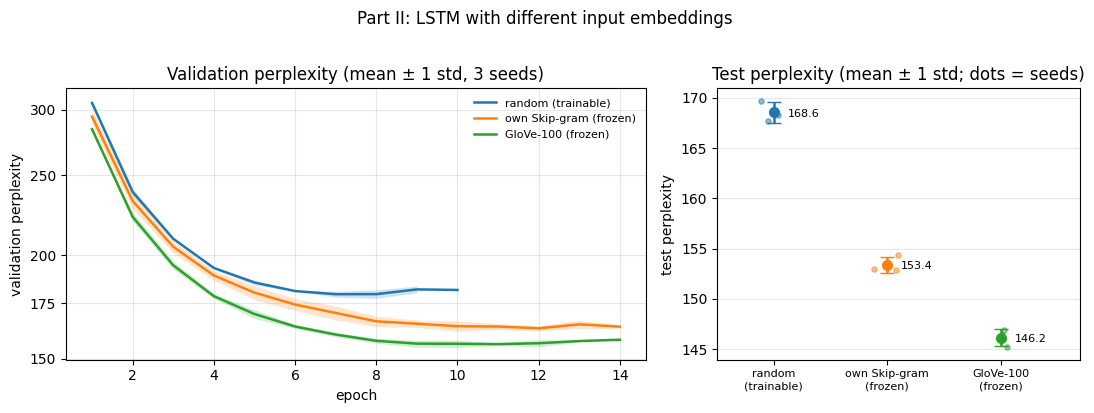

In [ ]:
# ==========================================
# CELL 10: CONVERGENCE / STABILITY FIGURE (mean ± std over seeds)
#   left : validation PPL per epoch, line = mean, band = ± 1 std across seeds
#   right: test PPL, marker = mean, bar = ± 1 std, dots = individual seeds
# ==========================================
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter, MaxNLocator

pub_short = PUBLIC_EMBEDDING.replace("glove-wiki-gigaword-", "GloVe-")          # -> "GloVe-100"
labels = {"random": "random (trainable)", "own_sg": "own Skip-gram (frozen)",
          "public": f"{pub_short} (frozen)"}
colors = {"random": "tab:blue", "own_sg": "tab:orange", "public": "tab:green"}

def curves(setting):
    """seeds x epochs array of validation PPL; NaN-padded if early stopping made runs differ in length."""
    hs = [r["history"]["valid_ppl"] for r in all_runs if r["setting"] == setting]
    n_ep = max(len(h) for h in hs)
    return np.array([h + [np.nan] * (n_ep - len(h)) for h in hs])

n = len(SEEDS)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})

all_ppl = []
for s in SETTINGS:
    c = curves(s)
    ep = np.arange(1, c.shape[1] + 1)
    mu = np.nanmean(c, 0)
    sd = np.nanstd(c, 0, ddof=1) if c.shape[0] > 1 else np.zeros_like(mu)
    ax.plot(ep, mu, color=colors[s], lw=1.8, label=labels[s])
    ax.fill_between(ep, mu - sd, mu + sd, color=colors[s], alpha=0.2, lw=0)
    all_ppl += list(c[~np.isnan(c)])

ax.set_yscale("log")
lo, hi = min(all_ppl), max(all_ppl)
ticks = [t for t in (100, 125, 150, 175, 200, 250, 300, 400, 500, 700, 1000) if lo * 0.95 <= t <= hi * 1.05]
ax.set_yticks(ticks)
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("epoch"); ax.set_ylabel("validation perplexity")
ax.set_title(f"Validation perplexity (mean ± 1 std, {n} seed{'s' if n > 1 else ''})")
ax.legend(fontsize=8, loc="upper right", frameon=False)
ax.grid(alpha=0.3, which="major")

# right panel: test PPL per setting
rng = np.random.default_rng(0)
for i, s in enumerate(SETTINGS):
    vals = runs.loc[runs.setting == s, "test_ppl"].to_numpy()
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    ax2.errorbar(i, vals.mean(), yerr=sd, fmt="o", color=colors[s], ms=7, capsize=5, lw=1.8)
    ax2.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, color=colors[s], s=14, alpha=0.5, zorder=3)
    ax2.annotate(f"{vals.mean():.1f}", (i, vals.mean()), xytext=(10, -3), textcoords="offset points", fontsize=8)
ax2.set_xticks(range(len(SETTINGS)))
ax2.set_xticklabels([labels[s].replace(" (", "\n(") for s in SETTINGS], fontsize=8)
ax2.set_xlim(-0.5, len(SETTINGS) - 0.3)
ax2.set_ylabel("test perplexity")
ax2.set_title("Test perplexity (mean ± 1 std; dots = seeds)")
ax2.grid(alpha=0.3, axis="y")

fig.suptitle("Part II: LSTM with different input embeddings", y=1.02)
fig.tight_layout()
fig.savefig(results_dir / "valid_curves_part2.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
# ==========================================
# CELL 11: GENERATION (matched to Part I decoding) -> results/part2/generations_part2.md
# ==========================================
PROMPTS = ["the history of this city", "in 1995 , the band", "the species was found",
           "during the war", "the film was released"]
DECODE = dict(max_new_tokens=30, temperature=0.8, top_k=40, seed=123)

@torch.no_grad()
def generate(model, prompt, max_new_tokens, temperature, top_k, seed, context_len=32):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    unk = token_to_id[UNK_TOKEN]
    ids = [token_to_id[START_TOKEN]] + [token_to_id.get(t, unk) for t in tokenize(prompt)]
    for _ in range(max_new_tokens):
        logits, _ = model(torch.tensor([ids[-context_len:]], device=device))
        logits = logits[0, -1].float() / temperature
        logits[token_to_id[PAD_TOKEN]] = -float("inf")
        topv, topi = torch.topk(logits, top_k)
        nxt = topi[torch.multinomial(torch.softmax(topv, -1), 1, generator=g)].item()
        if vocabulary[nxt] == END_TOKEN:
            break
        ids.append(nxt)
    return " ".join(vocabulary[i] for i in ids[1:])

gen_models = {}
for setting in SETTINGS:
    ckpt = torch.load(results_dir / f"lstm_{setting}_s{SEEDS[0]}.pt", map_location=device, weights_only=False)
    m = make_model(setting).to(device); m.load_state_dict(ckpt["model_state_dict"])
    gen_models[setting] = m

lines = [f"# Part II generations (seed-{SEEDS[0]} models; temperature={DECODE['temperature']}, "
         f"top-k={DECODE['top_k']}, max {DECODE['max_new_tokens']} tokens, seed={DECODE['seed']})\n"]
for prompt in PROMPTS:
    lines.append(f"## Prompt: `{prompt}`\n")
    for setting, m in gen_models.items():
        text = generate(m, prompt, **DECODE)
        lines.append(f"- **{labels[setting]}:** {text}")
        print(f"{setting:9s}| {text}")
    lines.append(""); print()
(results_dir / "generations_part2.md").write_text("\n".join(lines), encoding="utf-8")

random   | the history of this city is unknown , who was a major destination to provide assistance to establish such as the south american union ( fort ) , the largest in omaha .
own_sg   | the history of this city was the first <unk> in the area between the new island and new guinea . the two major tributaries of the mountain river is the most recent state of the
public   | the history of this city was the first way of the <unk> to the <unk> to the town who had been engaged by the royal defence of port - en - en <unk> , but

random   | in 1995 , the band was released as a single , " one of the highest best selling to the best band series " ( 1994 ) . " the album , the album has
own_sg   | in 1995 , the band ' s singles set in the song as well as clarkson ' s list of the charts , and on 2 may 1996 . the album had a single number
public   | in 1995 , the band moved to the country of the city as a single " <unk> in galveston " .

random   | the species was found on the day for a total of

2976

In [ ]:
# ==========================================
# CELL 12: PACKAGE PART II OUTPUTS FOR PART III (GitHub release)
# ==========================================
import zipfile

expected = [results_dir / f"{kind}_{s}_s{sd}.{ext}"
            for s in SETTINGS for sd in SEEDS
            for kind, ext in (("lstm", "pt"), ("result", "json"))]
missing = [str(p) for p in expected if not p.exists()]
assert not missing, f"Training not finished, missing: {missing}"

extra = sorted(results_dir.glob("coverage_*.json"))   # cell 8 output, for the report
zpath = Path("checkpoints.zip")
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for p in expected + extra:
        z.write(p, arcname=p.as_posix())               # keeps results/part2/... inside the zip

print(f"Wrote {zpath.resolve()} ({zpath.stat().st_size / 1e6:.0f} MB), {len(expected) + len(extra)} files:")
for name in zipfile.ZipFile(zpath).namelist():
    print("  ", name)

if IN_COLAB:
    from google.colab import files
    files.download(str(zpath))
elif IN_KAGGLE:
    print("Kaggle: download it from the Output panel (right sidebar) under "
          f"/kaggle/working/{REPO_NAME}/checkpoints.zip")
